# 🔧 02 — Preprocessing & Feature Engineering
### FraudShield | Phase 2 of the project tracker

**Goal:** turn raw IEEE-CIS columns into a model-ready feature table using **one shared, leakage-safe feature module** (`backend/app/features/`) that training and the FastAPI service both use.

| Tracker | Section | What happens |
|---|---|---|
| 2.1 | 1 | Time-based split from the EDA cutoffs (train / validation / holdout) |
| 2.5 | 1 | Holdout stays untouched (no fitting, no tuning on it) |
| 2.3 | 3 | Encoders fit on **train only** |
| 2.6 – 2.12 | 4 | Card key, velocity, amount-vs-history, novelty flags, time-since-last |
| 2.2 | 4 | Missing values: left as NaN for the GBDT model, plus explicit missing indicators |
| (safety) | 2, 6 | Leakage test + training/serving parity test |
| 2.4 | 7 | Feature schema + encoders saved for the API |
| 2.13 | — | Graph features deferred to Phase 8 (optional) |

### Design in one picture

```
raw transaction ──► CardHistoryStore.process()  ──► velocity / novelty / amount-vs-history  ┐
                ──► add_stateless_features()    ──► amount, time, email match, missing counts ├─► feature row ──► model
                ──► FeatureEncoders.transform() ──► category codes + frequencies             ┘
```

Training **replays the whole dataset in time order** through the same store the API will use. Each transaction's features are computed *before* it is added to history, so a transaction can only ever see the past.

### Rules this notebook enforces
1. Card-level features use **strictly earlier** transactions only.
2. **Fraud labels are never used as features** (in production, labels arrive days later).
3. Encoders are **fit on train only**.
4. Time is never shuffled.

**Prerequisites:** Phase 1 done (`ml/artifacts/eda_summary.json` exists), and `backend/app/features/` copied into the repo.
**Extra libs:** `pyarrow` (for saving Parquet; falls back to pickle if missing).

## 0. Setup

In [2]:
import gc
import json
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})

# ---- Paths (override with environment variables if your layout differs) ----
DATA_DIR      = Path(os.environ.get("FRAUD_DATA_DIR", "../../data/raw"))
PROCESSED_DIR = Path(os.environ.get("FRAUD_PROCESSED_DIR", "../../data/processed"))
ARTIFACTS_DIR = Path(os.environ.get("FRAUD_ARTIFACTS_DIR", "../artifacts"))
BACKEND_DIR   = Path(os.environ.get("FRAUD_BACKEND_DIR", "../../backend"))
FIG_DIR       = Path(os.environ.get("FRAUD_FIG_DIR", "../../docs/feature_figures"))
SAVE_FIGS     = True
COLORS        = {"legit": "#3B82F6", "fraud": "#EF4444", "neutral": "#94A3B8"}

# Make the shared feature module importable:  from app.features import ...
sys.path.insert(0, str(BACKEND_DIR.resolve()))
from app.features import (CardHistoryStore, FeatureEncoders, STATEFUL_FEATURES, STATELESS_FEATURES,
                          add_stateless_features, build_feature_frame, encoded_feature_names, replay)


def save_fig(name):
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


print("Backend dir  :", BACKEND_DIR.resolve())
print("Data dir     :", DATA_DIR.resolve())
print("Processed dir:", PROCESSED_DIR.resolve())

Backend dir  : C:\VS CODE\PROJECTS\FraudShield AI\backend
Data dir     : C:\VS CODE\PROJECTS\FraudShield AI\data\raw
Processed dir: C:\VS CODE\PROJECTS\FraudShield AI\data\processed


## 1. Load, merge, and time-split  *(tracker 2.1, 2.5)*

Same loading as the EDA notebook, plus the **`split`** column built from the cutoffs saved in `eda_summary.json`.

- **train**: fit encoders, tune and train models here
- **validation**: model selection, threshold tuning
- **holdout**: touched once at the very end, and used by the live simulator

In [3]:
def reduce_mem(df):
    for c in df.columns:
        t = df[c].dtype
        if isinstance(t, pd.CategoricalDtype):
            continue
        if t == "float64":
            df[c] = df[c].astype("float32")
        elif t == "int64":
            df[c] = pd.to_numeric(df[c], downcast="integer")
        elif t == "object" or pd.api.types.is_string_dtype(t):
            df[c] = df[c].astype("category")
    return df


txn   = reduce_mem(pd.read_csv(DATA_DIR / "train_transaction.csv"))
ident = reduce_mem(pd.read_csv(DATA_DIR / "train_identity.csv"))

has_identity = txn["TransactionID"].isin(ident["TransactionID"])
df = txn.merge(ident, on="TransactionID", how="left", validate="one_to_one")
df["has_identity"] = has_identity.values
del txn, ident, has_identity
gc.collect()

cfg = json.load(open(ARTIFACTS_DIR / "eda_summary.json"))["proposed_split"]
TRAIN_END, VAL_END = cfg["train_end_dt"], cfg["val_end_dt"]

df["split"] = np.select(
    [df["TransactionDT"] <= TRAIN_END, df["TransactionDT"] <= VAL_END],
    ["train", "validation"], default="holdout",
)

summary = df.groupby("split").agg(rows=("isFraud", "count"), fraud_rate=("isFraud", "mean"),
                                  first_dt=("TransactionDT", "min"), last_dt=("TransactionDT", "max"))
display(summary.loc[["train", "validation", "holdout"]])

# Safety checks: splits are strictly ordered in time
assert summary.loc["train", "last_dt"] < summary.loc["validation", "first_dt"] <= summary.loc["validation", "last_dt"] < summary.loc["holdout", "first_dt"]
print("OK: train < validation < holdout in time, no overlap.")

C:\Users\aksha\AppData\Local\Temp\ipykernel_23688\1560762789.py:20: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["has_identity"] = has_identity.values
C:\Users\aksha\AppData\Local\Temp\ipykernel_23688\1560762789.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["split"] = np.select(


,rows,fraud_rate,first_dt,last_dt
split,,,,
train,413378,0.0352,86400,10437996
validation,88581,0.0343,10438003,13151840
holdout,88581,0.0348,13151880,15811131


OK: train < validation < holdout in time, no overlap.


## 2. Leakage test — *before* building anything  *(safety)*

If a feature accidentally peeks at the future, the model looks great in validation and fails in production. This test catches that.

**Idea:** take the first 60,000 transactions (by time) and compute card-history features. Then **corrupt every transaction after row 30,000** (random amounts, cards, devices) and recompute. If the features of the first 30,000 rows are *identical*, the future cannot influence the past.

In [4]:
sub = df.sort_values(["TransactionDT", "TransactionID"]).head(60_000).reset_index(drop=True)
cut = 30_000

base_feats, _ = replay(sub)

rng = np.random.default_rng(42)
corrupted = sub.copy()
corrupted["TransactionAmt"] = corrupted["TransactionAmt"].astype("float64")
corrupted["card1"] = corrupted["card1"].astype("float64")
corrupted["DeviceInfo"] = corrupted["DeviceInfo"].astype(object)
corrupted.loc[cut:, "TransactionAmt"] = rng.random(len(sub) - cut) * 5000
corrupted.loc[cut:, "card1"] = rng.integers(0, 15000, len(sub) - cut).astype("float64")
corrupted.loc[cut:, "DeviceInfo"] = "FAKE_DEVICE"
corrupted_feats, _ = replay(corrupted)

pd.testing.assert_frame_equal(base_feats.iloc[:cut], corrupted_feats.iloc[:cut])
changed_later = not base_feats.iloc[cut:].equals(corrupted_feats.iloc[cut:])

print(f"PASS: features of the first {cut:,} transactions are identical after corrupting the future.")
print(f"Sanity check (later rows DO change when their own inputs change): {changed_later}")
del sub, base_feats, corrupted, corrupted_feats
gc.collect()

PASS: features of the first 30,000 transactions are identical after corrupting the future.
Sanity check (later rows DO change when their own inputs change): True


0

## 3. Fit encoders on **train only**  *(tracker 2.3)*

- **Low-cardinality** columns (`ProductCD`, `card4`, `card6`, `DeviceType`, `M1–M9`) become integer codes. Unseen values map to `-1`, missing stays `NaN`.
- **High-cardinality** columns (email domains, `DeviceInfo`, OS, browser, resolution) become **frequency encodings**: the share of train rows with that value. Unseen values get `0.0`.

Fitting on train only means validation and holdout see categories exactly as the live system would: sometimes unseen.

In [5]:
train_mask = (df["split"] == "train").to_numpy()

enc = FeatureEncoders().fit(df.loc[train_mask])
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
enc.to_json(ARTIFACTS_DIR / "encoders.json")

print(f"Fit on {enc.n_train:,} train rows -> saved {ARTIFACTS_DIR / 'encoders.json'}")
display(pd.DataFrame({
    "type": ["code"] * len(enc.categories) + ["frequency"] * len(enc.freqs),
    "n_values_kept": [len(v) for v in enc.categories.values()] + [len(v) for v in enc.freqs.values()],
}, index=list(enc.categories) + list(enc.freqs)))

# How often do validation / holdout contain values never seen in train? (tells you if encoders will be stale)
def unseen_share(col, mask):
    s = df.loc[mask, col].dropna().astype(str)
    known = set(enc.freqs.get(col, {}) or enc.categories.get(col, []))
    return float((~s.isin(known)).mean()) if len(s) else np.nan

rows = {c: {sp: unseen_share(c, (df["split"] == sp).to_numpy()) for sp in ["validation", "holdout"]}
        for c in ["P_emaildomain", "DeviceInfo", "id_31"] if c in df.columns}
display(pd.DataFrame(rows).T.rename_axis("unseen share of non-null values"))

Fit on 413,378 train rows -> saved ..\artifacts\encoders.json


,type,n_values_kept
ProductCD,code,5
card4,code,4
card6,code,4
DeviceType,code,2
M1,code,2
M2,code,2
M3,code,2
M4,code,3
M5,code,2
M6,code,2


,validation,holdout
unseen share of non-null values,,
P_emaildomain,0.0000,0.0000
DeviceInfo,0.0577,0.0609
id_31,0.0008,0.4522


## 4. Build the full feature table  *(tracker 2.2, 2.6 – 2.12)*

One call: `build_feature_frame(df, encoders)`. It

1. **Replays every transaction in time order** through `CardHistoryStore` (stateful features).
2. Adds **stateless** row features.
3. Applies the **encoders**.
4. Passes through the useful raw numeric columns (`TransactionAmt`, `card1/2/3/5`, `addr1/2`, `dist1/2`, `C1–C14`, `D1–D15`, `V1–V339`, `id_01–id_11`).

### Features created

| Group | Feature | Meaning |
|---|---|---|
| Card key (fine, "B") | `b_txn_count_10m / 1h / 24h` | Velocity: how many times this card was used recently (card testing) |
| | `b_amt_sum_1h / 24h` | Burst spending |
| | `b_hist_count`, `b_hist_amt_mean` | Card history depth and its usual amount |
| | `amt_vs_b_mean` | This amount ÷ the card's usual amount (past only) |
| | `b_time_since_last` | Seconds since the previous transaction on this card |
| | `new_device_flag`, `new_email_flag`, `new_addr_flag` | First time this card is seen with this device / email / address (NaN if unknown or no history) |
| Card key (coarse, "A") | `a_hist_count`, `a_hist_amt_mean`, `a_txn_count_1h / 24h`, `amt_vs_a_mean` | Same ideas on the coarser card group |
| Stateless | `amt_log`, `amt_cents` | Amount shape (fraud often uses distinctive cents) |
| | `hour_rel`, `dow_rel` | **Relative** hour / weekday (no real clock exists in the data) |
| | `email_match` | Purchaser vs recipient email: 1 match, 0 mismatch, NaN unknown |
| | `has_identity`, `addr_missing`, `r_email_present`, `n_null_D`, `n_null_id` | Explicit missingness signals from the EDA |

### Why both card keys?
From the EDA: Key A had 43,071 groups (40.4% singleton, median size 2) and Key B had 222,518 groups (58.0% singleton). Key A is **coarse** and probably merges different cardholders; Key B is **finer** but leaves many cards with no history. Its higher "fraud concentration" number (91.7% vs 77.7%) is partly just a result of bigger groups, so it is not a fair way to pick a winner. We give the model **both** and let it decide.

### Missing values (2.2)
Gradient-boosted trees (XGBoost / LightGBM) handle `NaN` natively, so we do **not** fill with means. Missingness is kept as signal, plus explicit indicators above.

In [6]:
t0 = time.time()
feats = build_feature_frame(df, enc)
elapsed = time.time() - t0

print(f"Built {feats.shape[1]} features for {feats.shape[0]:,} transactions in {elapsed:,.0f}s "
      f"({elapsed / len(feats) * 1000:.2f} ms/row, includes history replay)")
print(f"Memory: {feats.memory_usage(deep=True).sum() / 1e9:.2f} GB | dtypes: {sorted(set(feats.dtypes.astype(str)))}")

assert not np.isinf(feats.to_numpy()).any(), "inf values found"
assert len(feats) == len(df)

groups = {
    "stateful (card history)": STATEFUL_FEATURES,
    "stateless (row-level)": STATELESS_FEATURES,
    "encoded categoricals": encoded_feature_names(),
}
rows = []
for name, cols in groups.items():
    rows.append({"group": name, "n_features": len(cols)})
rows.append({"group": "raw passthrough (amount, card, addr, C, D, V, id_01-11)",
             "n_features": feats.shape[1] - sum(len(c) for c in groups.values())})
display(pd.DataFrame(rows).set_index("group"))

Built 434 features for 590,540 transactions in 12s (0.02 ms/row, includes history replay)
Memory: 1.03 GB | dtypes: ['float32']


,n_features
group,
stateful (card history),17
stateless (row-level),10
encoded categoricals,19
"raw passthrough (amount, card, addr, C, D, V, id_01-11)",388


In [7]:
# Look at the engineered columns: how often are they missing / zero, and what do they look like?
eng_cols = STATEFUL_FEATURES + STATELESS_FEATURES
profile = pd.DataFrame({
    "null_%": feats[eng_cols].isna().mean() * 100,
    "zero_%": (feats[eng_cols] == 0).mean() * 100,
    "mean": feats[eng_cols].mean(),
    "p50": feats[eng_cols].median(),
    "p99": feats[eng_cols].quantile(0.99),
})
display(profile.round(3))

# Cold start: share of transactions whose card (Key B) has NO earlier history
cold = (feats["b_hist_count"] == 0).groupby(df["split"]).mean().loc[["train", "validation", "holdout"]]
print("Cold-start share (card has no history) per split:")
display(cold.to_frame("share_with_no_history"))

,null_%,zero_%,mean,p50,p99
b_hist_count,0.0000,37.6800,6.2140,1.0000,53.0000
b_hist_amt_mean,37.6800,0.0000,126.2910,78.9500,894.3160
b_txn_count_10m,0.0000,90.7260,0.1610,0.0000,2.0000
b_txn_count_1h,0.0000,84.2240,0.4450,0.0000,4.0000
b_txn_count_24h,0.0000,71.1980,1.9590,0.0000,23.0000
b_amt_sum_1h,0.0000,84.2240,54.2330,0.0000,774.0000
b_amt_sum_24h,0.0000,71.1980,202.0780,0.0000,"2,208.0000"
b_time_since_last,37.6800,0.0130,"850,821.6250","161,276.9844","7,784,200.0000"
amt_vs_b_mean,37.6800,0.0000,1.2230,0.9840,6.9930
new_device_flag,89.6550,6.5450,0.3670,0.0000,1.0000


Cold-start share (card has no history) per split:


,share_with_no_history
split,
train,0.4068
validation,0.3094
holdout,0.3044


> **Cold start matters.** A large share of transactions come from cards with no earlier history, so velocity features are blank for them. That is normal, and exactly why we keep both card keys plus raw columns: the model must still score new cards. In the live demo, a manually typed transaction from an unseen card is a cold-start case.

## 5. Do the new features carry signal?  *(sanity check, train split only)*

We only look at the **train** split here, so the holdout stays untouched.

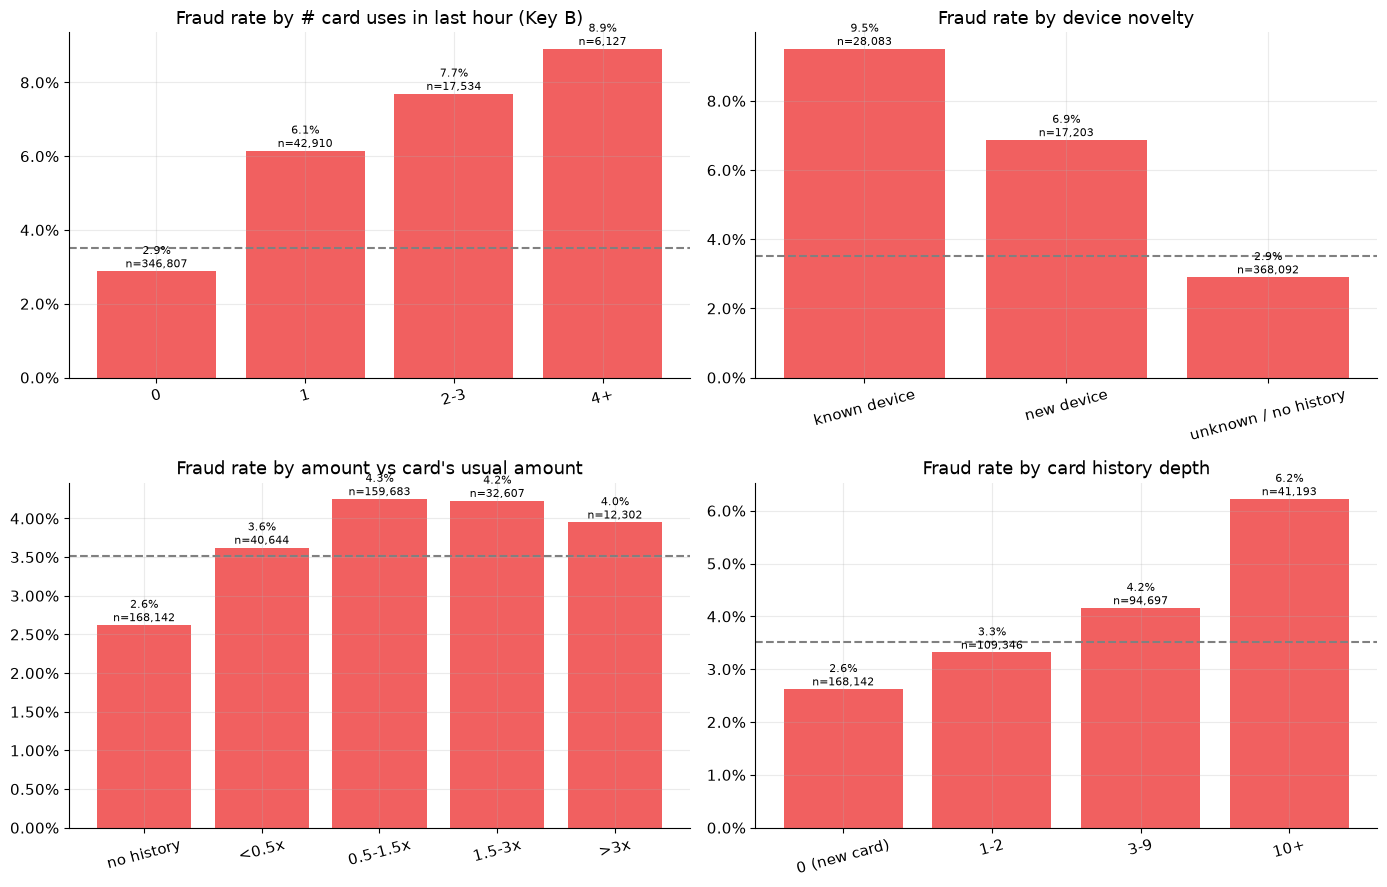

In [8]:
f = feats.loc[train_mask]
y_tr = df.loc[train_mask, "isFraud"]
overall = y_tr.mean()


def rate_by(ax, labels, order, title):
    s = pd.Series(labels, index=f.index)
    t = y_tr.groupby(s).agg(count="count", rate="mean").reindex(order)
    ax.bar(range(len(t)), t["rate"].fillna(0), color=COLORS["fraud"], alpha=0.85)
    for i, (r, c) in enumerate(zip(t["rate"], t["count"])):
        if c == c:
            ax.text(i, 0 if r != r else r, f"{r:.1%}\nn={int(c):,}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=15)
    ax.axhline(overall, ls="--", color="gray")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title)


fig, axes = plt.subplots(2, 2, figsize=(14, 9))

c1h = f["b_txn_count_1h"]
lab = np.select([c1h == 0, c1h == 1, c1h <= 3], ["0", "1", "2-3"], default="4+")
rate_by(axes[0, 0], lab, ["0", "1", "2-3", "4+"], "Fraud rate by # card uses in last hour (Key B)")

nd = f["new_device_flag"]
lab = np.select([nd == 1, nd == 0], ["new device", "known device"], default="unknown / no history")
rate_by(axes[0, 1], lab, ["known device", "new device", "unknown / no history"], "Fraud rate by device novelty")

r = f["amt_vs_b_mean"]
lab = np.select([r.isna(), r < 0.5, r < 1.5, r < 3], ["no history", "<0.5x", "0.5-1.5x", "1.5-3x"], default=">3x")
rate_by(axes[1, 0], lab, ["no history", "<0.5x", "0.5-1.5x", "1.5-3x", ">3x"], "Fraud rate by amount vs card's usual amount")

h = f["b_hist_count"]
lab = np.select([h == 0, h <= 2, h <= 9], ["0 (new card)", "1-2", "3-9"], default="10+")
rate_by(axes[1, 1], lab, ["0 (new card)", "1-2", "3-9", "10+"], "Fraud rate by card history depth")

plt.tight_layout()
save_fig("01_feature_signal_checks")
plt.show()
del f, y_tr

In [9]:
# Quick numeric view: correlation of every ENGINEERED feature with fraud (train only)
tr = feats.loc[train_mask, eng_cols]
corr = tr.corrwith(df.loc[train_mask, "isFraud"].astype("float32")).dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)
display(top.to_frame("corr_with_isFraud"))
print("Weak linear correlation is normal for fraud; tree models use interactions. Real importance comes in Phase 3 / SHAP.")
del tr

c:\VS CODE\PROJECTS\FraudShield AI\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\VS CODE\PROJECTS\FraudShield AI\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,corr_with_isFraud
addr_missing,0.1512
n_null_id,-0.1412
r_email_present,0.1307
has_identity,0.1240
email_match,0.0937
n_null_D,-0.0907
b_time_since_last,-0.0803
b_txn_count_10m,0.0762
b_txn_count_1h,0.0737
a_txn_count_1h,0.0593


Weak linear correlation is normal for fraud; tree models use interactions. Real importance comes in Phase 3 / SHAP.


## 6. Training / serving parity  *(safety, tracker 5.10 early)*

The API receives **plain JSON-like values**, while training uses **pandas with category / float32 dtypes**. If those two paths ever disagree, the model is silently fed different numbers in production.

We feed the first 20,000 transactions through the store **as plain Python dicts** (exactly what FastAPI will do) and compare against the batch result.

In [10]:
sub = df.sort_values(["TransactionDT", "TransactionID"]).head(20_000).reset_index(drop=True)
batch_feats, _ = replay(sub)

need = ["TransactionID", "TransactionDT", "TransactionAmt", "card1", "card2", "card3", "card4", "card5",
        "card6", "addr1", "addr2", "D1", "DeviceInfo", "P_emaildomain"]
records = sub[need].astype(object).to_dict("records")          # plain Python values, like an API request body

api_store = CardHistoryStore()
got = pd.DataFrame([api_store.process(rec) for rec in records], columns=STATEFUL_FEATURES)

np.testing.assert_allclose(got.to_numpy("float64"), batch_feats.to_numpy("float64"), rtol=1e-6, atol=1e-9, equal_nan=True)
print(f"PASS: {len(sub):,} transactions give identical stateful features through the batch path and the API-style path.")

# Stateless features: one-row DataFrame (serving) vs full DataFrame (training)
full_stateless = add_stateless_features(sub)
for i in np.random.default_rng(0).choice(len(sub), 50, replace=False):
    pd.testing.assert_frame_equal(full_stateless.iloc[[i]], add_stateless_features(sub.iloc[[i]]))
print("PASS: stateless features identical for single-row and batch input (50 random rows).")
del sub, batch_feats, records, got, api_store, full_stateless
gc.collect()

PASS: 20,000 transactions give identical stateful features through the batch path and the API-style path.
PASS: stateless features identical for single-row and batch input (50 random rows).


20

## 7. Save outputs  *(tracker 2.4)*

| File | Used by |
|---|---|
| `data/processed/features.parquet` | Phase 3 modeling (features + `isFraud` + `split`) |
| `ml/artifacts/encoders.json` | FastAPI (already saved in section 3) |
| `ml/artifacts/feature_schema.json` | FastAPI and training: exact column list and order |

In [11]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
meta = df[["TransactionID", "TransactionDT", "isFraud", "split"]]
out = pd.concat([meta, feats], axis=1)

try:
    out_path = PROCESSED_DIR / "features.parquet"
    out.to_parquet(out_path, index=False)
except ImportError:
    out_path = PROCESSED_DIR / "features.pkl"
    out.to_pickle(out_path)
print(f"Saved {out_path}  ({out_path.stat().st_size / 1e6:,.0f} MB)  shape={out.shape}")

schema = {
    "n_features": int(feats.shape[1]),
    "feature_order": list(feats.columns),
    "dtype": "float32",
    "groups": {
        "stateful": STATEFUL_FEATURES,
        "stateless": STATELESS_FEATURES,
        "encoded": encoded_feature_names(),
    },
    "target": "isFraud",
    "split_cutoffs": {"train_end_dt": TRAIN_END, "val_end_dt": VAL_END},
    "notes": [
        "hour_rel/dow_rel are relative to an unknown reference, not clock time",
        "card history features need CardHistoryStore warmed up with train+validation transactions at API startup",
    ],
}
with open(ARTIFACTS_DIR / "feature_schema.json", "w") as fh:
    json.dump(schema, fh, indent=2)
print("Saved", ARTIFACTS_DIR / "feature_schema.json")

Saved ..\..\data\processed\features.parquet  (99 MB)  shape=(590540, 438)
Saved ..\artifacts\feature_schema.json


## 8. Summary & handoff

### Tracker updates (Phase 2)

| # | Task | Status |
|---|---|---|
| 2.1 | Time-based split (train / validation / holdout) | ✅ |
| 2.2 | Missing values: NaN kept for GBDT + explicit indicators | ✅ |
| 2.3 | Encoders fit on train only | ✅ |
| 2.4 | Feature schema + encoders saved | ✅ |
| 2.5 | Holdout untouched | ✅ (never used for fitting or inspection) |
| 2.6 | Card pseudo-ID (Keys A and B) | ✅ |
| 2.7 – 2.8 | Velocity counts and amount sums | ✅ |
| 2.9 | `amt_vs_b_mean` | ✅ |
| 2.10 – 2.11 | New device / email / address flags | ✅ |
| 2.12 | `b_time_since_last` | ✅ |
| 2.13 | Graph features | ⏭ deferred to Phase 8 |

### Things to remember for later phases
- **Serving needs a warm store.** At API startup, replay train + validation transactions through `CardHistoryStore` so live cards have history. For the demo, the simulator then streams the **holdout** period.
- **Out-of-order events:** the store assumes non-decreasing `TransactionDT` per card. Fine for the replay simulator; a real system would need ordering guarantees.
- **A manually typed transaction is usually a cold start** (no card history, no `D1`). Test the model on cold-start rows specifically in Phase 3.
- **Not included yet:** `id_12 – id_38` categoricals (other than OS / browser / resolution), and graph features. Candidates for a Phase 3 experiment if time allows.

### Write the interview story
> *"I discovered that card identity doesn't exist in the data, so I reconstructed it with two heuristic keys. I built velocity and novelty features by replaying transactions in time order through the same store the API uses, and proved with a corruption test that future data can't change past features, and that training and serving produce identical numbers."*

---
**Next:** Phase 3 — `03_Modeling.ipynb` (baseline, XGBoost, LightGBM; PR-AUC and recall at fixed false-positive rate on the time-based validation split).